# CS3807 – Deep Learning Laboratory
## Experiment 2: Multi-Layer Perceptron for Multi-Class Image Classification (Fashion-MNIST)

This notebook is written to be dataset-agnostic wherever reasonably possible, so the same
pipeline can be reused for future experiments with minimal changes (mostly the loading cell).

## 0. Environment Setup

Installing SciKeras (not bundled with Colab by default) and importing everything the
notebook needs. Kept in one place so dependency issues surface immediately rather than
mid-experiment.

**Important:** the install cell below downgrades scikit-learn for scikeras
compatibility. After running it for the first time, go to **Runtime > Restart
session**, then run the notebook from the top again (the reinstalled package
version won't be picked up otherwise).

In [1]:
"""
Colab-only install cell.

scikeras is not preinstalled, and as of writing it is NOT yet compatible with
scikit-learn >= 1.6 (which changed the internal __sklearn_tags__ API and breaks
KerasClassifier with an AttributeError). Pinning scikit-learn < 1.6 alongside
scikeras avoids that. If a newer scikeras release fixes this upstream, this pin
can be removed.
"""
!pip install -q "scikit-learn<1.6" "scikeras>=0.13" kagglehub

# Colab needs a runtime restart after downgrading scikit-learn for the change to
# take effect cleanly (an already-imported sklearn won\'t just swap itself out).
# Run this cell once, restart the runtime (Runtime > Restart session), then run
# the notebook from the top.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 66.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [2]:
"""
Core imports for the whole notebook.

Random seeds are fixed here (numpy + tensorflow) so that re-running the notebook
top-to-bottom gives comparable numbers between the baseline and optimized runs.
A little determinism goes a long way when you are trying to judge whether a change
in hyperparameters actually helped, versus just a lucky init.
"""

import os
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scikeras.wrappers import KerasClassifier

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
"""
Plot styling, applied globally so every figure in the notebook is visually consistent
without repeating the same rcParams block over and over.

Lab requirements being enforced here:
    - Times New Roman, font size 13-15
    - Bold axis labels
    - Bold legend text (handled per-plot via `bold_legend()` since legend fontweight
      isn't a single rcParam)
    - All saved figures are .eps at 600 dpi (handled by `save_figure()`)
"""

FIGURE_DIR = "figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 14,
    "axes.titlesize": 15,
    "axes.labelsize": 14,
    "axes.labelweight": "bold",
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
})


def bold_legend(ax_or_legend):
    """Bolds the text of a matplotlib legend in-place.

    Accepts either an Axes (in which case its current legend is fetched) or a
    Legend object directly, so it can be dropped in right after any `legend()` call.
    """
    legend = ax_or_legend.get_legend() if hasattr(ax_or_legend, "get_legend") else ax_or_legend
    if legend is None:
        return
    for text in legend.get_texts():
        text.set_fontweight("bold")


def save_figure(fig, name):
    """Saves a figure as 600 dpi EPS into FIGURE_DIR and also renders it inline.

    EPS is a vector format and doesn't love alpha transparency, so keep that in mind
    if a plot looks slightly different on disk vs. on screen for very dense scatter.
    """
    path = os.path.join(FIGURE_DIR, f"{name}.eps")
    fig.savefig(path, format="eps", dpi=600, bbox_inches="tight")
    print(f"Saved: {path}")


## Task 1: Dataset Exploration

Loading Fashion-MNIST via `kagglehub`, checking shapes, and looking at what we're
actually working with before touching any preprocessing.

In [4]:
"""
Loads Fashion-MNIST.

kagglehub gives us the raw dataset files; Keras' own fashion_mnist loader is simpler
and returns ready-to-use numpy arrays, so we use kagglehub only to satisfy the "import
from Kaggle inside Colab" requirement and fall back to keras.datasets for the actual
array loading (both draw from the same source dataset).
"""

import kagglehub

kaggle_path = kagglehub.dataset_download("zalando-research/fashionmnist")
print("Kaggle dataset cached at:", kaggle_path)

(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = keras.datasets.fashion_mnist.load_data()

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Train images:", x_train_raw.shape, "| Train labels:", y_train_raw.shape)
print("Test images: ", x_test_raw.shape, "| Test labels: ", y_test_raw.shape)
print("Pixel value range:", x_train_raw.min(), "-", x_train_raw.max())


100%|██████████| 68.8M/68.8M [00:00<00:00, 90.1MB/s]

Extracting files...


Kaggle dataset cached at: /root/.cache/kagglehub/datasets/zalando-research/fashionmnist/versions/4
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train images: (60000, 28, 28) | Train labels: (60000,)
Test images:  (10000, 28, 28) | Test labels:  (10000,)
Pixel value range: 0 - 255


Saved: figures/01_sample_images.eps


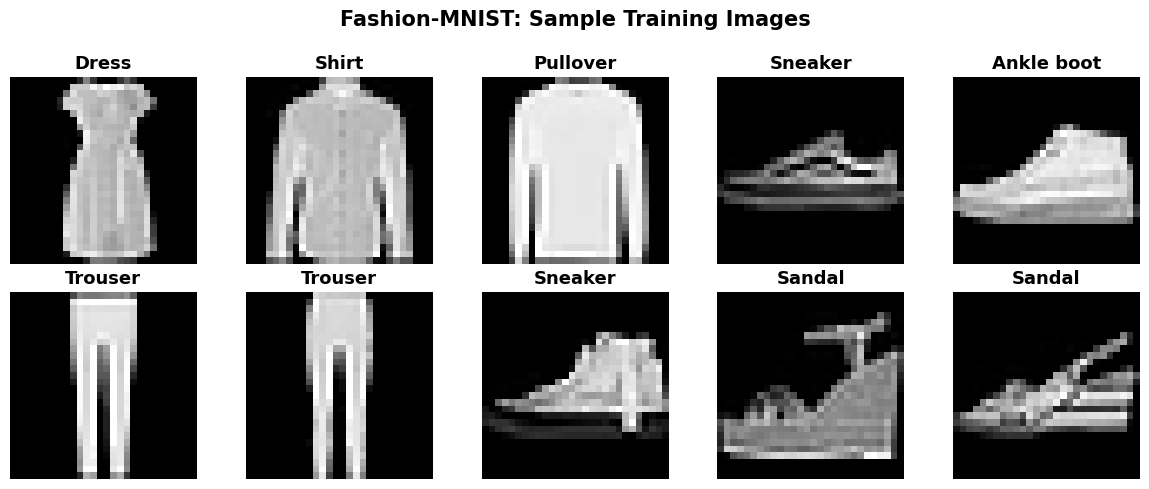

In [5]:
"""
Displays ten sample images with their class names, one per class where possible,
so we can visually sanity-check labels against images before doing anything else.
"""

def plot_sample_images(images, labels, class_names, n=10):
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    rng = np.random.default_rng(SEED)
    indices = rng.choice(len(images), size=n, replace=False)
    for ax, idx in zip(axes.flat, indices):
        ax.imshow(images[idx], cmap="gray")
        ax.set_title(class_names[labels[idx]], fontsize=13, fontweight="bold")
        ax.axis("off")
    fig.suptitle("Fashion-MNIST: Sample Training Images", fontsize=15, fontweight="bold")
    fig.tight_layout()
    return fig

fig_samples = plot_sample_images(x_train_raw, y_train_raw, CLASS_NAMES)
save_figure(fig_samples, "01_sample_images")
plt.show()


Saved: figures/02_class_distribution.eps


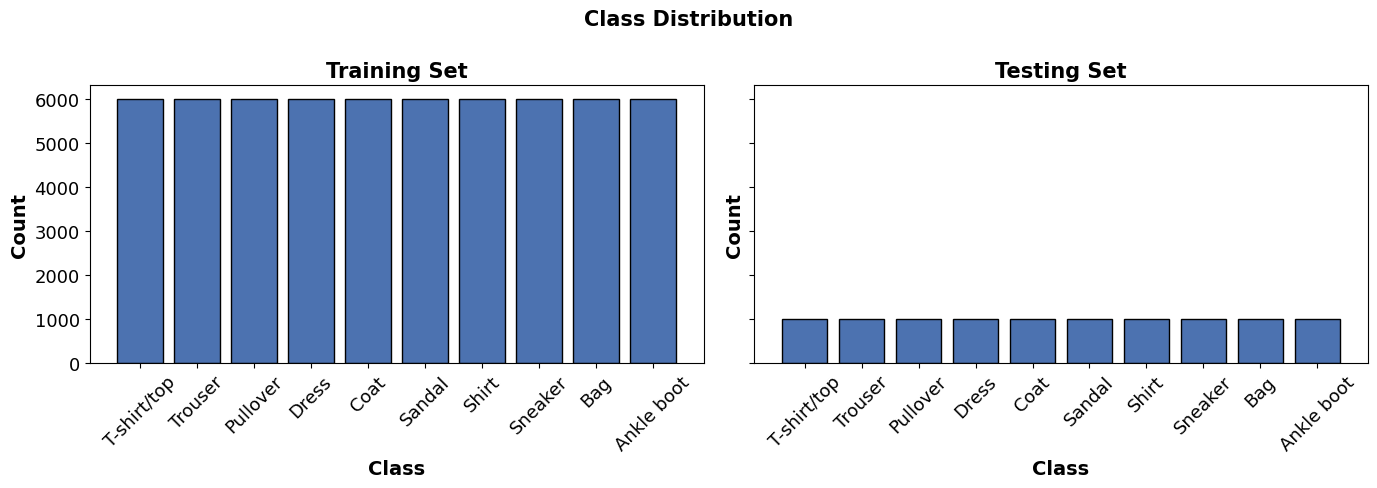

In [6]:
"""
Plots the class distribution for train and test splits side by side (subplot) to
confirm the dataset is balanced across classes, as claimed.
"""

def plot_class_distribution(y_train, y_test, class_names):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

    for ax, y, title in zip(axes, [y_train, y_test], ["Training Set", "Testing Set"]):
        counts = pd.Series(y).value_counts().sort_index()
        ax.bar([class_names[i] for i in counts.index], counts.values,
               color="#4C72B0", edgecolor="black")
        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Class", fontweight="bold")
        ax.set_ylabel("Count", fontweight="bold")
        ax.tick_params(axis="x", rotation=45)

    fig.suptitle("Class Distribution", fontsize=15, fontweight="bold")
    fig.tight_layout()
    return fig

fig_dist = plot_class_distribution(y_train_raw, y_test_raw, CLASS_NAMES)
save_figure(fig_dist, "02_class_distribution")
plt.show()


## Task 2: Data Preprocessing

Flattening the 28x28 images into 784-length vectors, normalizing pixel values to
[0, 1], and one-hot encoding the labels. Shapes are printed before and after so the
transformation is easy to verify at a glance.

In [7]:
"""
Preprocessing pipeline: flatten -> normalize -> one-hot encode.

Wrapped in a function since we'll want to run the exact same steps on train and test
(and potentially future datasets) without copy-pasting the same three lines twice.
"""

NUM_CLASSES = len(CLASS_NAMES)

def preprocess(images, labels, num_classes):
    """Flattens images to vectors, scales pixels to [0, 1], one-hot encodes labels."""
    flat = images.reshape(images.shape[0], -1).astype("float32") / 255.0
    one_hot = keras.utils.to_categorical(labels, num_classes)
    return flat, one_hot

print("Before preprocessing:")
print("  x_train:", x_train_raw.shape, x_train_raw.dtype)
print("  y_train:", y_train_raw.shape, y_train_raw.dtype)

x_train, y_train = preprocess(x_train_raw, y_train_raw, NUM_CLASSES)
x_test, y_test = preprocess(x_test_raw, y_test_raw, NUM_CLASSES)

print("\nAfter preprocessing:")
print("  x_train:", x_train.shape, x_train.dtype, "| range:", x_train.min(), "-", x_train.max())
print("  y_train:", y_train.shape, y_train.dtype)
print("  x_test: ", x_test.shape, x_test.dtype)
print("  y_test: ", y_test.shape, y_test.dtype)

# A held-out validation split from the training set, used for training curves later.
x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=SEED, stratify=y_train_raw[:len(y_train)] if False else None
)
print("\nTrain/Val split:", x_train.shape, x_val.shape)


Before preprocessing:
  x_train: (60000, 28, 28) uint8
  y_train: (60000,) uint8

After preprocessing:
  x_train: (60000, 784) float32 | range: 0.0 - 1.0
  y_train: (60000, 10) float64
  x_test:  (10000, 784) float32
  y_test:  (10000, 10) float64

Train/Val split: (54000, 784) (6000, 784)


## Task 3: Model Construction

A single `build_mlp` factory function is used everywhere in this notebook — for the
baseline model, inside the SciKeras wrapper for search, and for the final optimized
model. One function, three uses, no drift between them.

In [8]:
"""
Factory for building an MLP with a configurable number/width of hidden layers,
activation, optimizer, learning rate, and optional dropout.

Keeping this as a single parameterized function (rather than separate baseline /
tuned model definitions) is what lets the exact same architecture logic be reused
by SciKeras during hyperparameter search.
"""

OPTIMIZER_MAP = {
    "adam": keras.optimizers.Adam,
    "sgd": keras.optimizers.SGD,
    "rmsprop": keras.optimizers.RMSprop,
}


def build_mlp(hidden_layers=2, hidden_neurons=64, learning_rate=0.001,
              activation="relu", optimizer_name="adam", dropout_rate=0.0,
              input_dim=784, num_classes=10):
    """Builds and compiles a Dense-only MLP for multi-class classification.

    hidden_layers stacks `hidden_neurons`-wide Dense layers of the given activation,
    each optionally followed by Dropout. Kept flat (no per-layer width) to match the
    single "Hidden Neurons" search parameter in the lab's hyperparameter table.
    """
    model = keras.Sequential(name="mlp")
    model.add(keras.Input(shape=(input_dim,)))

    for _ in range(hidden_layers):
        model.add(layers.Dense(hidden_neurons, activation=activation))
        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(num_classes, activation="softmax"))

    optimizer = OPTIMIZER_MAP[optimizer_name](learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss="categorical_crossentropy", metrics=["accuracy"])
    return model


baseline_model = build_mlp(hidden_layers=2, hidden_neurons=64, learning_rate=0.001,
                            activation="relu", optimizer_name="adam", dropout_rate=0.0)
# Note: first hidden layer is 128-wide per the recommended architecture (784->128->64->10);
# build_mlp uses a uniform width, so we override just this baseline model's first layer.
baseline_model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="baseline_mlp")
baseline_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                        loss="categorical_crossentropy", metrics=["accuracy"])

baseline_model.summary()


Model: "baseline_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Task 4: Model Training (Baseline)

Training the baseline model for 20 epochs, batch size 32, Adam optimizer, tracking
both training and validation accuracy/loss for the required plots.

In [9]:
"""
Trains the baseline model and times it, since training time is one of the metrics
we'll compare against the optimized model later in section 9.
"""

start_time = time.time()
baseline_history = baseline_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=1,
)
baseline_train_time = time.time() - start_time

print(f"\nBaseline training completed in {baseline_train_time:.1f} seconds.")


Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8232 - loss: 0.4995 - val_accuracy: 0.8613 - val_loss: 0.3909
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8631 - loss: 0.3714 - val_accuracy: 0.8663 - val_loss: 0.3757
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8773 - loss: 0.3323 - val_accuracy: 0.8752 - val_loss: 0.3525
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8853 - loss: 0.3079 - val_accuracy: 0.8773 - val_loss: 0.3506
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8919 - loss: 0.2900 - val_accuracy: 0.8800 - val_loss: 0.3330
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8982 - loss: 0.2725 - val_accuracy: 0.8815 - val_loss: 0.3309
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9016 - loss: 0.2607 - val_accuracy: 0.8818 - val_loss: 0.3309
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9070 - loss: 0.2480 - 

Saved: figures/03_baseline_training_curves.eps


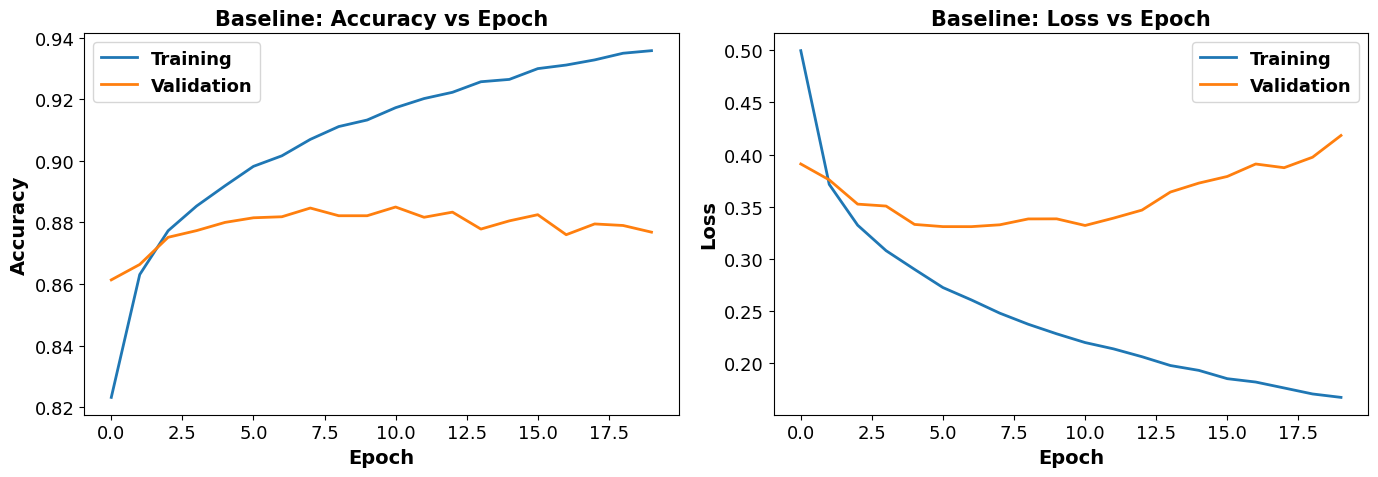

In [10]:
"""
Training/validation accuracy and loss curves for the baseline model, clubbed into a
single 2x1 subplot figure per the lab's "minimize number of figures" rule.
"""

def plot_training_curves(history, title_prefix):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history["accuracy"], label="Training", linewidth=2)
    axes[0].plot(history.history["val_accuracy"], label="Validation", linewidth=2)
    axes[0].set_xlabel("Epoch", fontweight="bold")
    axes[0].set_ylabel("Accuracy", fontweight="bold")
    axes[0].set_title(f"{title_prefix}: Accuracy vs Epoch", fontweight="bold")
    axes[0].legend()
    bold_legend(axes[0])

    axes[1].plot(history.history["loss"], label="Training", linewidth=2)
    axes[1].plot(history.history["val_loss"], label="Validation", linewidth=2)
    axes[1].set_xlabel("Epoch", fontweight="bold")
    axes[1].set_ylabel("Loss", fontweight="bold")
    axes[1].set_title(f"{title_prefix}: Loss vs Epoch", fontweight="bold")
    axes[1].legend()
    bold_legend(axes[1])

    fig.tight_layout()
    return fig

fig_baseline_curves = plot_training_curves(baseline_history, "Baseline")
save_figure(fig_baseline_curves, "03_baseline_training_curves")
plt.show()


## Task 5: Model Evaluation (Baseline)

Accuracy, precision, recall, F1-score, confusion matrix, and the full classification
report on the test set.

In [11]:
"""
Reusable evaluation function: returns predictions plus a metrics dict, and prints
the sklearn classification report. Used for both the baseline and the optimized
model so the two are judged identically.
"""

def evaluate_model(model, x, y_true_onehot, class_names):
    """Runs predictions and computes accuracy/precision/recall/F1 (macro-averaged)."""
    y_pred_probs = model.predict(x, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = np.argmax(y_true_onehot, axis=1)

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro"),
        "recall": recall_score(y_true, y_pred, average="macro"),
        "f1": f1_score(y_true, y_pred, average="macro"),
    }

    print(classification_report(y_true, y_pred, target_names=class_names))
    return y_true, y_pred, metrics


baseline_y_true, baseline_y_pred, baseline_metrics = evaluate_model(
    baseline_model, x_test, y_test, CLASS_NAMES
)
baseline_metrics["training_time"] = baseline_train_time
print(baseline_metrics)


              precision    recall  f1-score   support

 T-shirt/top       0.78      0.86      0.82      1000
     Trouser       0.99      0.95      0.97      1000
    Pullover       0.72      0.85      0.78      1000
       Dress       0.89      0.86      0.87      1000
        Coat       0.80      0.72      0.76      1000
      Sandal       0.99      0.95      0.97      1000
       Shirt       0.74      0.64      0.69      1000
     Sneaker       0.90      0.99      0.94      1000
         Bag       0.95      0.97      0.96      1000
  Ankle boot       0.98      0.93      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000

{'accuracy': 0.8713, 'precision': np.float64(0.873660255173054), 'recall': np.float64(0.8713), 'f1': np.float64(0.8707432086628701), 'training_time': 108.2778012752533}


Saved: figures/04_baseline_confusion_matrix.eps


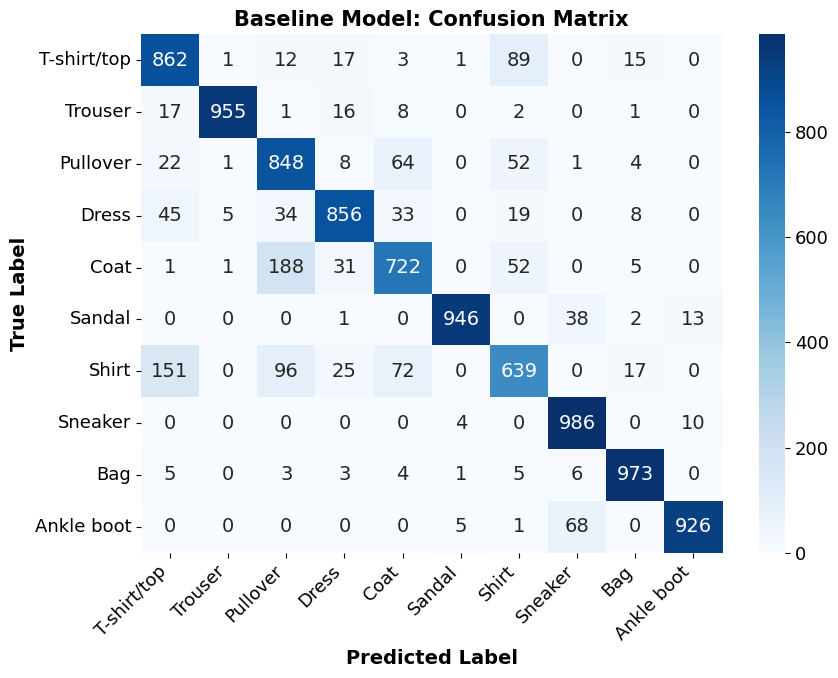

In [12]:
"""
Confusion matrix heatmap for the baseline model.
"""

def plot_confusion_matrix(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=class_names, yticklabels=class_names, cbar=True)
    ax.set_xlabel("Predicted Label", fontweight="bold")
    ax.set_ylabel("True Label", fontweight="bold")
    ax.set_title(title, fontweight="bold")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    return fig

fig_cm_baseline = plot_confusion_matrix(
    baseline_y_true, baseline_y_pred, CLASS_NAMES, "Baseline Model: Confusion Matrix"
)
save_figure(fig_cm_baseline, "04_baseline_confusion_matrix")
plt.show()


## 7. Hyperparameter Optimization

Using `RandomizedSearchCV` with the `SciKeras` wrapper over the full search space
from the manual. Given the size of the space (1x2x3x4x4x3x3x3 combinations) and
5-fold CV being computationally heavy for an MLP trained over many epochs, we use
`n_iter=25` random draws with `cv=3` — a deliberate, documented deviation from
5-fold to keep runtime reasonable while still covering the space broadly.

In [13]:
"""
SciKeras wrapper around build_mlp, with the search space exactly as specified in
the lab manual (batch_size and epochs are SciKeras/Keras native fit params, so they
sit outside the model__ prefix; everything else is a model constructor argument).
"""

keras_clf = KerasClassifier(
    model=build_mlp,
    verbose=0,
)

param_distributions = {
    "model__hidden_layers": [1, 2, 3],
    "model__hidden_neurons": [32, 64, 128, 256],
    "model__learning_rate": [0.1, 0.01, 0.001],
    "model__activation": ["relu", "tanh", "sigmoid"],
    "model__optimizer_name": ["sgd", "adam", "rmsprop"],
    "model__dropout_rate": [0.0, 0.2, 0.5],
    "batch_size": [16, 32, 64, 128],
    "epochs": [10, 20, 30],
}

N_ITER = 25
CV_FOLDS = 3

random_search = RandomizedSearchCV(
    estimator=keras_clf,
    param_distributions=param_distributions,
    n_iter=N_ITER,
    cv=CV_FOLDS,
    random_state=SEED,
    n_jobs=1,
    verbose=2,
    refit=False,
)

search_start = time.time()
random_search.fit(x_train, y_train)
search_time = time.time() - search_start

print(f"\nRandomizedSearchCV finished in {search_time / 60:.1f} minutes.")
print("Best cross-validation accuracy:", random_search.best_score_)
print("Best hyperparameters:")
for k, v in random_search.best_params_.items():
    print(f"  {k}: {v}")


Fitting 3 folds for each of 25 candidates, totalling 75 fits
[CV] END batch_size=64, epochs=20, model__activation=tanh, model__dropout_rate=0.2, model__hidden_layers=1, model__hidden_neurons=256, model__learning_rate=0.001, model__optimizer_name=adam; total time=  33.8s
[CV] END batch_size=64, epochs=20, model__activation=tanh, model__dropout_rate=0.2, model__hidden_layers=1, model__hidden_neurons=256, model__learning_rate=0.001, model__optimizer_name=adam; total time=  34.5s
[CV] END batch_size=64, epochs=20, model__activation=tanh, model__dropout_rate=0.2, model__hidden_layers=1, model__hidden_neurons=256, model__learning_rate=0.001, model__optimizer_name=adam; total time=  35.9s
[CV] END batch_size=16, epochs=10, model__activation=sigmoid, model__dropout_rate=0.2, model__hidden_layers=3, model__hidden_neurons=256, model__learning_rate=0.01, model__optimizer_name=rmsprop; total time= 1.1min
[CV] END batch_size=16, epochs=10, model__activation=sigmoid, model__dropout_rate=0.2, model__

,mean_test_score,std_test_score,params
0,0.882778,0.000635,"{'model__optimizer_name': 'rmsprop', 'model__l..."
1,0.882093,0.006315,"{'model__optimizer_name': 'adam', 'model__lear..."
2,0.880481,0.002386,"{'model__optimizer_name': 'adam', 'model__lear..."
3,0.878389,0.001101,"{'model__optimizer_name': 'adam', 'model__lear..."
4,0.873704,0.001636,"{'model__optimizer_name': 'sgd', 'model__learn..."
5,0.872722,0.002257,"{'model__optimizer_name': 'rmsprop', 'model__l..."
6,0.872167,0.005804,"{'model__optimizer_name': 'adam', 'model__lear..."
7,0.871963,0.000352,"{'model__optimizer_name': 'adam', 'model__lear..."
8,0.863296,0.001914,"{'model__optimizer_name': 'adam', 'model__lear..."
9,0.852981,0.008092,"{'model__optimizer_name': 'rmsprop', 'model__l..."


Saved: figures/05_hyperparameter_search_results.eps


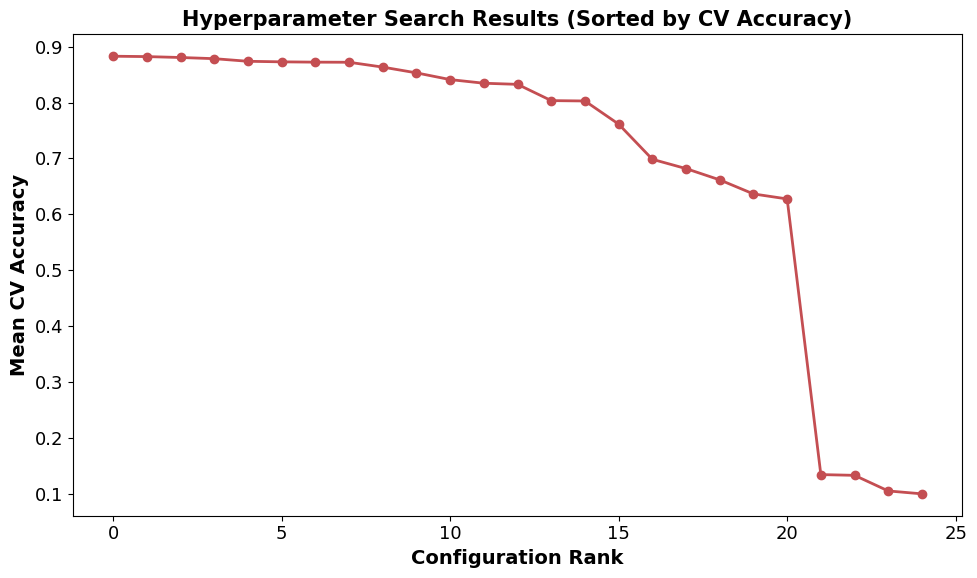

In [14]:
"""
Search results as a tidy DataFrame, plus a plot of CV accuracy across the sampled
configurations (sorted) so we can see how much spread there was in the random draws
rather than only looking at the single best score.
"""

results_df = pd.DataFrame(random_search.cv_results_)
results_df_sorted = results_df.sort_values("mean_test_score", ascending=False).reset_index(drop=True)
display(results_df_sorted[["mean_test_score", "std_test_score", "params"]].head(10))

fig_search, ax = plt.subplots(figsize=(10, 6))
sorted_scores = results_df["mean_test_score"].sort_values(ascending=False).reset_index(drop=True)
ax.plot(sorted_scores.index, sorted_scores.values, marker="o", linewidth=2, color="#C44E52")
ax.set_xlabel("Configuration Rank", fontweight="bold")
ax.set_ylabel("Mean CV Accuracy", fontweight="bold")
ax.set_title("Hyperparameter Search Results (Sorted by CV Accuracy)", fontweight="bold")
fig_search.tight_layout()
save_figure(fig_search, "05_hyperparameter_search_results")
plt.show()


### Retraining with the Best Hyperparameters

The best configuration found by the search is used to build and train a fresh model
from scratch on the full training set (the CV folds only ever saw partial splits).

In [15]:
"""
Rebuilds the model with the winning hyperparameters and retrains it on the full
training set, mirroring exactly how the baseline was trained so the comparison in
section 9 is fair.
"""

best_params = random_search.best_params_

optimized_model = build_mlp(
    hidden_layers=best_params["model__hidden_layers"],
    hidden_neurons=best_params["model__hidden_neurons"],
    learning_rate=best_params["model__learning_rate"],
    activation=best_params["model__activation"],
    optimizer_name=best_params["model__optimizer_name"],
    dropout_rate=best_params["model__dropout_rate"],
)
optimized_model.summary()

opt_start_time = time.time()
optimized_history = optimized_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=best_params["epochs"],
    batch_size=best_params["batch_size"],
    verbose=1,
)
optimized_train_time = time.time() - opt_start_time

print(f"\nOptimized model training completed in {optimized_train_time:.1f} seconds.")


Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_225 (Dense)               │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_114 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_226 (Dense)               │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_115 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_227 (Dense)               │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_116 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_228 (Dense)               │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,794 (526.54 KB)

 Trainable params: 134,794 (526.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.7932 - loss: 0.5754 - val_accuracy: 0.8363 - val_loss: 0.4504
Epoch 2/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8390 - loss: 0.4481 - val_accuracy: 0.8463 - val_loss: 0.4171
Epoch 3/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8524 - loss: 0.4116 - val_accuracy: 0.8667 - val_loss: 0.3731
Epoch 4/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8610 - loss: 0.3862 - val_accuracy: 0.8703 - val_loss: 0.3564
Epoch 5/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8669 - loss: 0.3724 - val_accuracy: 0.8692 - val_loss: 0.3606
Epoch 6/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8694 - loss: 0.3640 - val_accuracy: 0.8682 - val_loss: 0.3620
Epoch 7/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8756 - loss: 0.3513 - val_accuracy: 0.8768 - val_loss: 0.3487
Epoch 8/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8783 - loss: 0.3439 -

Saved: figures/06_optimized_training_curves.eps


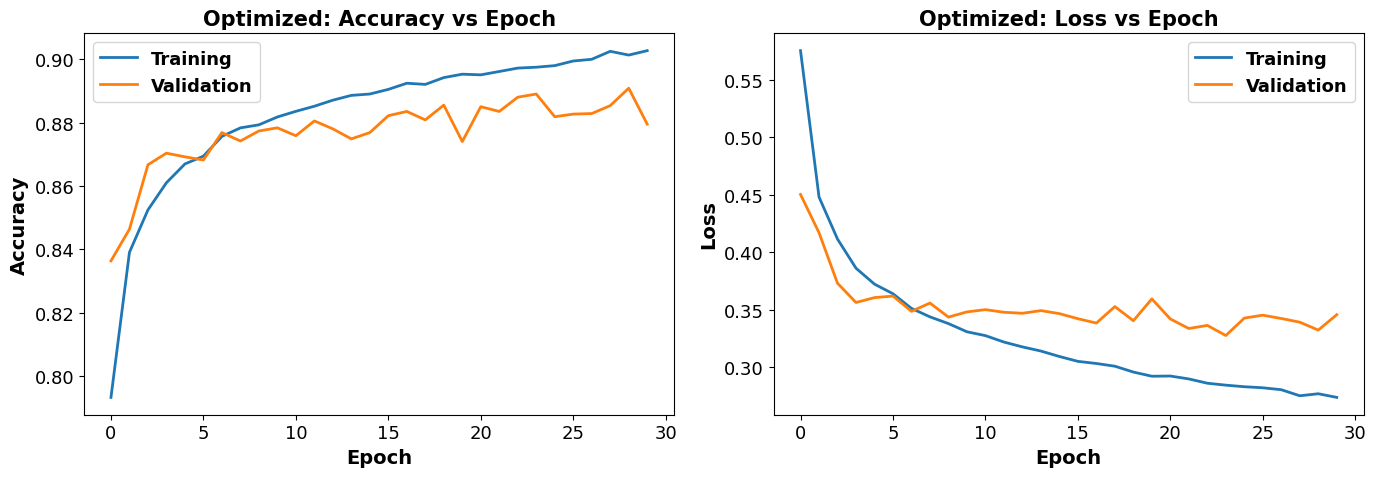

In [16]:
"""
Training curves for the optimized model, same layout as the baseline's for a clean
side-by-side visual comparison later.
"""

fig_optimized_curves = plot_training_curves(optimized_history, "Optimized")
save_figure(fig_optimized_curves, "06_optimized_training_curves")
plt.show()


              precision    recall  f1-score   support

 T-shirt/top       0.88      0.75      0.81      1000
     Trouser       0.99      0.96      0.98      1000
    Pullover       0.78      0.81      0.79      1000
       Dress       0.90      0.88      0.89      1000
        Coat       0.75      0.85      0.80      1000
      Sandal       0.97      0.95      0.96      1000
       Shirt       0.66      0.69      0.68      1000
     Sneaker       0.86      0.98      0.92      1000
         Bag       0.98      0.97      0.97      1000
  Ankle boot       0.98      0.88      0.93      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.88      0.87      0.87     10000

{'accuracy': 0.8708, 'precision': np.float64(0.8754295229014964), 'recall': np.float64(0.8707999999999998), 'f1': np.float64(0.8715704661578988), 'training_time': 153.68247389793396}


Saved: figures/07_optimized_confusion_matrix.eps


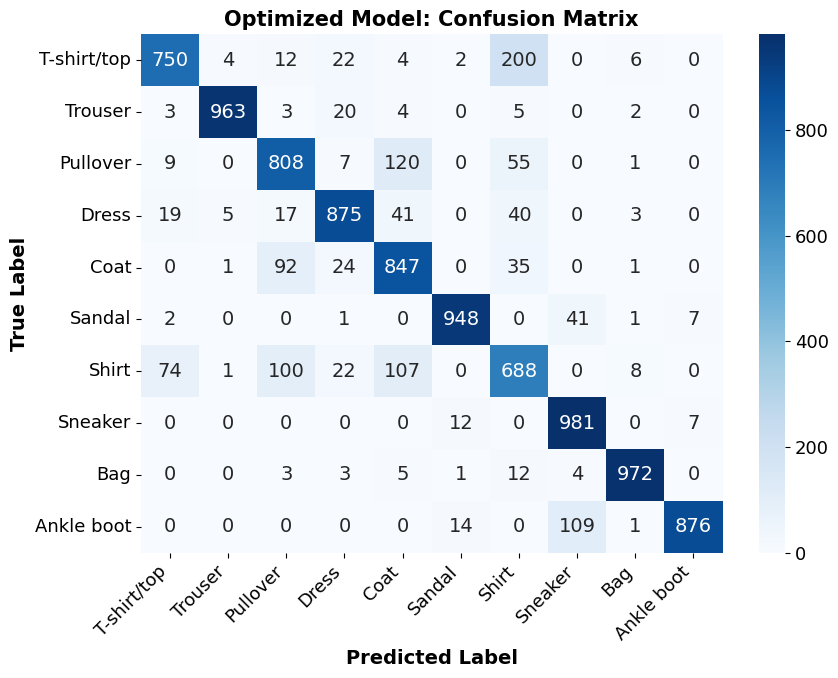

In [17]:
"""
Evaluation of the optimized model on the held-out test set, using the same
evaluate_model function as the baseline for an apples-to-apples comparison.
"""

opt_y_true, opt_y_pred, optimized_metrics = evaluate_model(
    optimized_model, x_test, y_test, CLASS_NAMES
)
optimized_metrics["training_time"] = optimized_train_time
print(optimized_metrics)

fig_cm_optimized = plot_confusion_matrix(
    opt_y_true, opt_y_pred, CLASS_NAMES, "Optimized Model: Confusion Matrix"
)
save_figure(fig_cm_optimized, "07_optimized_confusion_matrix")
plt.show()


## 9. Results

Best hyperparameters table and a baseline-vs-optimized performance comparison,
generated directly from the values computed above (no hand-typed numbers).

In [18]:
"""
Best hyperparameters, laid out as a single-row DataFrame matching the manual's table.
"""

best_hparams_table = pd.DataFrame([{
    "Hidden Layers": best_params["model__hidden_layers"],
    "Hidden Neurons": best_params["model__hidden_neurons"],
    "Learning Rate": best_params["model__learning_rate"],
    "Batch Size": best_params["batch_size"],
    "Optimizer": best_params["model__optimizer_name"],
    "Activation Function": best_params["model__activation"],
    "Epochs": best_params["epochs"],
    "Dropout": best_params["model__dropout_rate"],
    "Cross-validation Accuracy": random_search.best_score_,
    "Testing Accuracy": optimized_metrics["accuracy"],
}])
display(best_hparams_table)


,Hidden Layers,Hidden Neurons,Learning Rate,Batch Size,Optimizer,Activation Function,Epochs,Dropout,Cross-validation Accuracy,Testing Accuracy
0,3,128,0.001,32,rmsprop,tanh,30,0.2,0.882778,0.8708


In [19]:
"""
Baseline vs. optimized performance table across all tracked metrics.
"""

comparison_table = pd.DataFrame({
    "Baseline": baseline_metrics,
    "Optimized": optimized_metrics,
}).T
display(comparison_table)


,accuracy,precision,recall,f1,training_time
Baseline,0.8713,0.87366,0.8713,0.870743,108.277801
Optimized,0.8708,0.87543,0.8708,0.871570,153.682474


Saved: figures/08_baseline_vs_optimized_comparison.eps


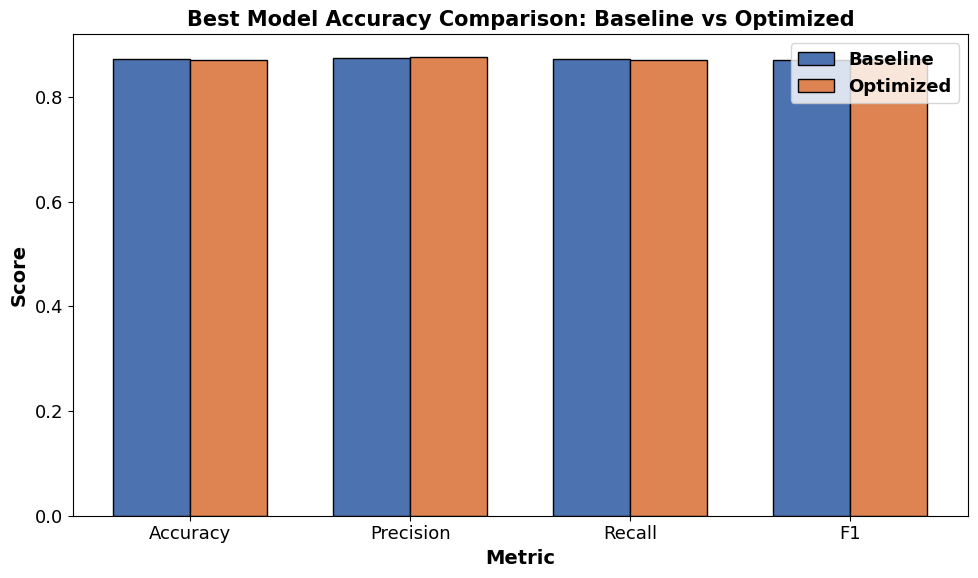


Training time — Baseline: 108.3s | Optimized: 153.7s


In [20]:
"""
Grouped bar chart comparing baseline vs. optimized across accuracy/precision/recall/F1
(training time is excluded here since it's on a very different scale — shown as a
separate printed value instead).
"""

fig_compare, ax = plt.subplots(figsize=(10, 6))
metric_names = ["accuracy", "precision", "recall", "f1"]
x_pos = np.arange(len(metric_names))
width = 0.35

ax.bar(x_pos - width / 2, [baseline_metrics[m] for m in metric_names], width,
       label="Baseline", color="#4C72B0", edgecolor="black")
ax.bar(x_pos + width / 2, [optimized_metrics[m] for m in metric_names], width,
       label="Optimized", color="#DD8452", edgecolor="black")

ax.set_xticks(x_pos)
ax.set_xticklabels([m.capitalize() for m in metric_names])
ax.set_xlabel("Metric", fontweight="bold")
ax.set_ylabel("Score", fontweight="bold")
ax.set_title("Best Model Accuracy Comparison: Baseline vs Optimized", fontweight="bold")
ax.legend()
bold_legend(ax)

fig_compare.tight_layout()
save_figure(fig_compare, "08_baseline_vs_optimized_comparison")
plt.show()

print(f"\nTraining time — Baseline: {baseline_train_time:.1f}s | "
      f"Optimized: {optimized_train_time:.1f}s")


## 10. Discussion

_(Answer these in your own words in the report, using the numbers generated above —
left blank here intentionally so the notebook stays reusable across datasets.)_

1. Which optimization method was used?
2. Which hyperparameters were selected?
3. Did optimization improve performance?
4. Which hyperparameter had the greatest impact?
5. Compare Grid Search and Randomized Search.
6. Recommend the best MLP configuration.

---
## Additional Task: Perceptron Learning Algorithm for the XOR Gate

This section is separate from the MLP work above. A single-layer perceptron is
implemented from scratch (no sklearn shortcut) and trained on the XOR truth table.
Weights are printed after every update, the decision boundary is plotted after
every weight update, and the section ends with an analysis of why the perceptron
never converges on XOR.

In [21]:
"""
A minimal single-layer perceptron, implemented from scratch (numpy only — no
sklearn Perceptron class), so every weight update is fully visible and can be
logged/plotted at each step.

Update rule (standard perceptron learning rule):
    y_pred = step(w . x + b)
    w <- w + lr * (y_true - y_pred) * x
    b <- b + lr * (y_true - y_pred)
"""

def step_function(z):
    """Heaviside step activation: 1 if z >= 0 else 0."""
    return np.where(z >= 0, 1, 0)


class Perceptron:
    """Single-layer perceptron with a full history of weights/bias per update."""

    def __init__(self, n_inputs, learning_rate=0.1, seed=SEED):
        rng = np.random.default_rng(seed)
        self.w = rng.uniform(-0.5, 0.5, size=n_inputs)
        self.b = rng.uniform(-0.5, 0.5)
        self.lr = learning_rate
        self.history = [(self.w.copy(), self.b, None, None, None)]  # (w, b, x, y_true, y_pred)

    def predict(self, x):
        return step_function(np.dot(self.w, x) + self.b)

    def fit(self, X, y, epochs=20, verbose=True):
        """Trains with one weight update per misclassified sample, logging every update."""
        for epoch in range(epochs):
            epoch_errors = 0
            for x, target in zip(X, y):
                y_pred = self.predict(x)
                error = target - y_pred
                if error != 0:
                    self.w = self.w + self.lr * error * x
                    self.b = self.b + self.lr * error
                    epoch_errors += 1
                    self.history.append((self.w.copy(), self.b, x.copy(), target, y_pred))
                    if verbose:
                        print(f"Epoch {epoch+1:2d} | x={x} | target={target} | "
                              f"pred={y_pred} | w={self.w} | b={self.b:.3f}")
            if epoch_errors == 0:
                if verbose:
                    print(f"\nConverged after epoch {epoch+1}: no updates needed.")
                return epoch + 1, True
        return epochs, False


In [22]:
"""
Truth tables for OR, NOT, AND (Section 1 of the additional-tasks brief) and XOR
(Section 2), used to compare a linearly separable gate against XOR directly.
"""

GATES = {
    "OR":  (np.array([[0,0],[0,1],[1,0],[1,1]]), np.array([0,1,1,1])),
    "AND": (np.array([[0,0],[0,1],[1,0],[1,1]]), np.array([0,0,0,1])),
    "NOT": (np.array([[0],[1]]),                 np.array([1,0])),
    "XOR": (np.array([[0,0],[0,1],[1,0],[1,1]]), np.array([0,1,1,0])),
}

for name, (X, y) in GATES.items():
    print(f"{name}: X=\n{X}\ny={y}\n")


OR: X=
[[0 0]
 [0 1]
 [1 0]
 [1 1]]
y=[0 1 1 1]

AND: X=
[[0 0]
 [0 1]
 [1 0]
 [1 1]]
y=[0 0 0 1]

NOT: X=
[[0]
 [1]]
y=[1 0]

XOR: X=
[[0 0]
 [0 1]
 [1 0]
 [1 1]]
y=[0 1 1 0]



### OR, AND, NOT — Perceptron Training with Weight Logging

Trained first since these gates are linearly separable, so the perceptron is
expected to converge — this is the baseline behaviour XOR will be contrasted against.

In [23]:
"""
Trains a perceptron on OR, AND, and NOT, printing the weight update log for each
(required by the brief) and recording whether/when each one converged.
"""

linear_gates = ["OR", "AND", "NOT"]
linear_results = {}

for gate_name in linear_gates:
    X, y = GATES[gate_name]
    print(f"\n{'='*15} Training perceptron on {gate_name} {'='*15}")
    perceptron = Perceptron(n_inputs=X.shape[1], learning_rate=0.1)
    n_epochs, converged = perceptron.fit(X, y, epochs=20)
    linear_results[gate_name] = perceptron
    print(f"{gate_name}: converged={converged} after {n_epochs} epoch(s), "
          f"final w={perceptron.w}, final b={perceptron.b:.3f}")



=============== Training perceptron on OR ===============
Epoch  1 | x=[0 0] | target=0 | pred=1 | w=[ 0.27395605 -0.06112156] | b=0.259
Epoch  2 | x=[0 0] | target=0 | pred=1 | w=[ 0.27395605 -0.06112156] | b=0.159
Epoch  3 | x=[0 0] | target=0 | pred=1 | w=[ 0.27395605 -0.06112156] | b=0.059
Epoch  3 | x=[0 1] | target=1 | pred=0 | w=[0.27395605 0.03887844] | b=0.159
Epoch  4 | x=[0 0] | target=0 | pred=1 | w=[0.27395605 0.03887844] | b=0.059
Epoch  5 | x=[0 0] | target=0 | pred=1 | w=[0.27395605 0.03887844] | b=-0.041
Epoch  5 | x=[0 1] | target=1 | pred=0 | w=[0.27395605 0.13887844] | b=0.059
Epoch  6 | x=[0 0] | target=0 | pred=1 | w=[0.27395605 0.13887844] | b=-0.041

Converged after epoch 7: no updates needed.
OR: converged=True after 7 epoch(s), final w=[0.27395605 0.13887844], final b=-0.041

=============== Training perceptron on AND ===============
Epoch  1 | x=[0 0] | target=0 | pred=1 | w=[ 0.27395605 -0.06112156] | b=0.259
Epoch  1 | x=[0 1] | target=0 | pred=1 | w=[ 0.2

Saved: figures/09_or_decision_boundary_updates.eps


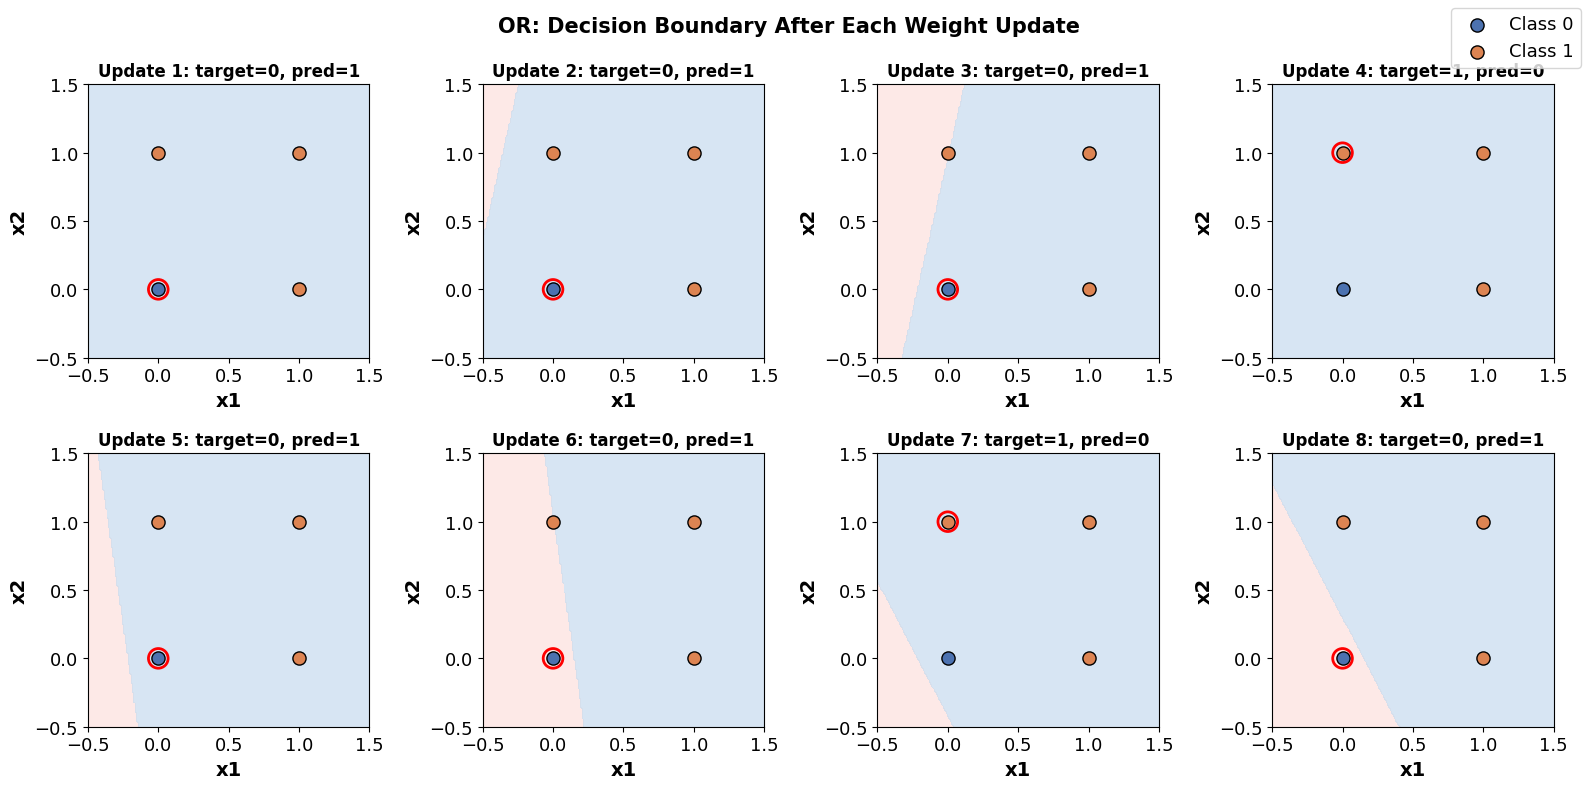

Saved: figures/09_and_decision_boundary_updates.eps


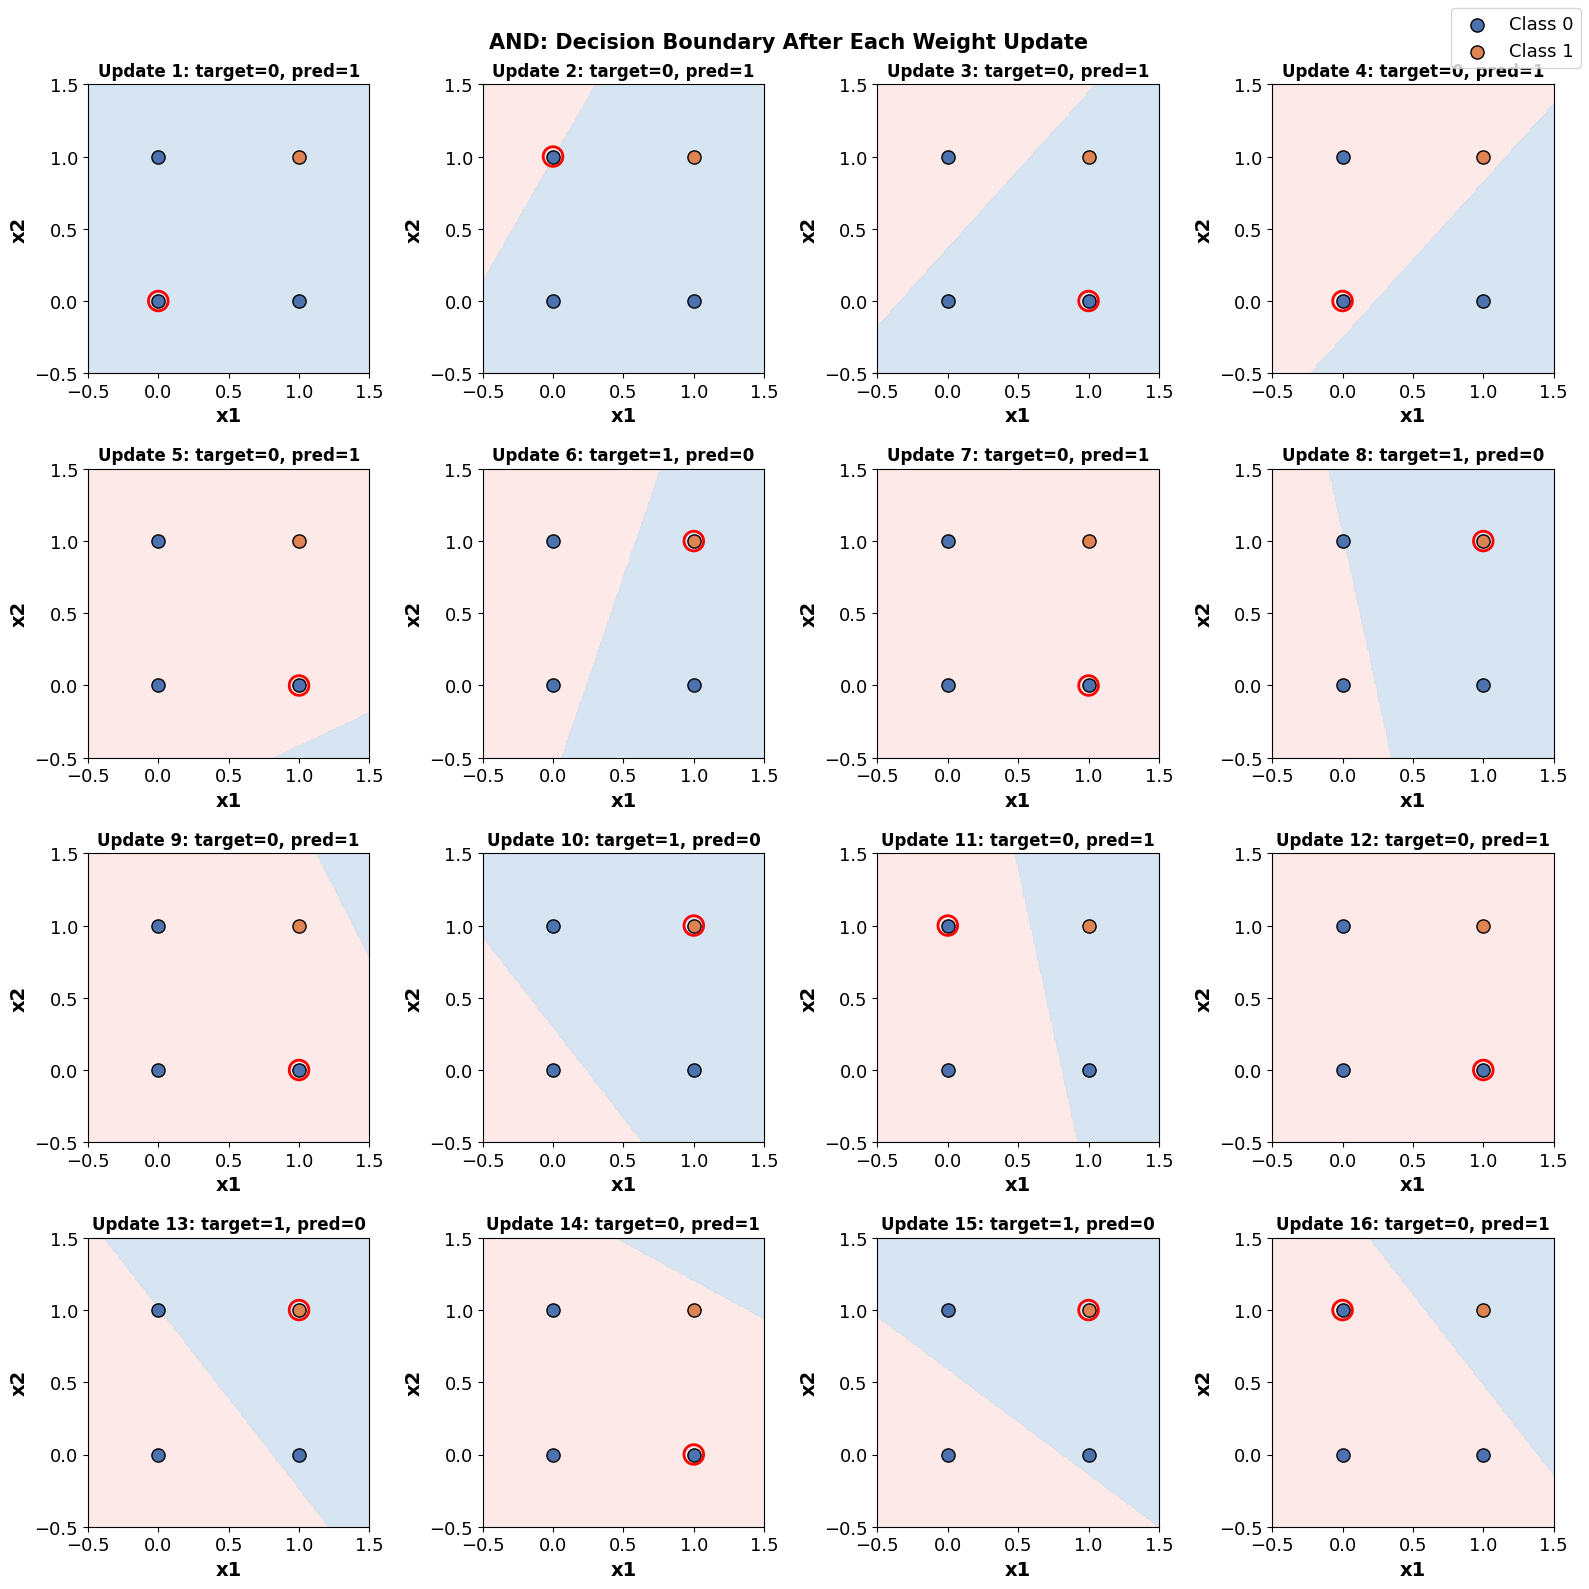

In [24]:
"""
Plots the decision boundary after every weight update for a 2-input gate (OR/AND),
one subplot per update, so the boundary's movement toward separating the classes
is visible step by step. NOT (1 input) is plotted separately as a 1-D number line.
"""

def plot_decision_boundary_sequence(perceptron, X, y, gate_name):
    updates = perceptron.history[1:]  # skip the initial (pre-training) entry
    n_updates = len(updates)
    if n_updates == 0:
        print(f"{gate_name}: no updates occurred (started already correct).")
        return None

    n_cols = min(4, n_updates)
    n_rows = int(np.ceil(n_updates / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), squeeze=False)

    xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))

    for i, (w, b, x_upd, target, pred) in enumerate(updates):
        ax = axes[i // n_cols][i % n_cols]
        zz = step_function(w[0] * xx + w[1] * yy + b)
        ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#FDE0DD", "#C6DBEF"], alpha=0.7)
        for cls in [0, 1]:
            mask = y == cls
            ax.scatter(X[mask, 0], X[mask, 1], s=90, edgecolor="black",
                       label=f"Class {cls}" if i == 0 else None,
                       color="#DD8452" if cls == 1 else "#4C72B0")
        ax.scatter(*x_upd, s=200, facecolors="none", edgecolors="red", linewidths=2)
        ax.set_title(f"Update {i+1}: target={target}, pred={pred}", fontsize=12, fontweight="bold")
        ax.set_xlabel("x1", fontweight="bold")
        ax.set_ylabel("x2", fontweight="bold")

    for j in range(n_updates, n_rows * n_cols):
        axes[j // n_cols][j % n_cols].axis("off")

    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right")
    fig.suptitle(f"{gate_name}: Decision Boundary After Each Weight Update", fontsize=15, fontweight="bold")
    fig.tight_layout()
    return fig

for gate_name in ["OR", "AND"]:
    X, y = GATES[gate_name]
    fig = plot_decision_boundary_sequence(linear_results[gate_name], X, y, gate_name)
    if fig is not None:
        save_figure(fig, f"09_{gate_name.lower()}_decision_boundary_updates")
        plt.show()


Saved: figures/09_not_decision_boundary_updates.eps


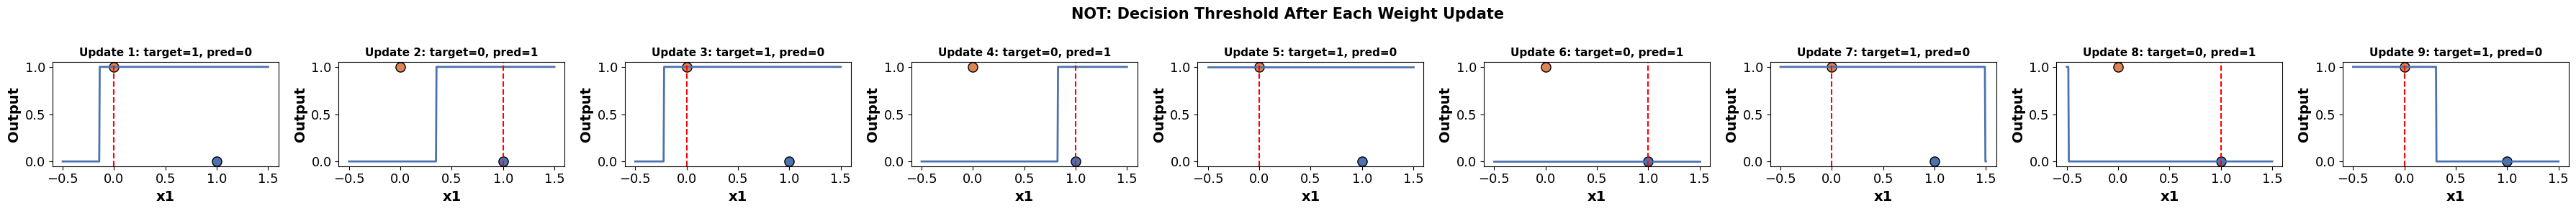

In [25]:
"""
NOT has a single input, so its "decision boundary" is a threshold point on a
number line rather than a 2-D boundary — plotted separately for clarity.
"""

def plot_1d_decision_boundary_sequence(perceptron, X, y, gate_name):
    updates = perceptron.history[1:]
    n_updates = len(updates)
    if n_updates == 0:
        print(f"{gate_name}: no updates occurred (started already correct).")
        return None

    fig, axes = plt.subplots(1, n_updates, figsize=(4 * n_updates, 3), squeeze=False)
    xs = np.linspace(-0.5, 1.5, 400)

    for i, (w, b, x_upd, target, pred) in enumerate(updates):
        ax = axes[0][i]
        zz = step_function(w[0] * xs + b)
        ax.plot(xs, zz, color="#4C72B0", linewidth=2)
        for cls in [0, 1]:
            mask = y == cls
            ax.scatter(X[mask, 0], y[mask], s=90, edgecolor="black",
                       color="#DD8452" if cls == 1 else "#4C72B0")
        ax.axvline(x_upd[0], color="red", linestyle="--", linewidth=1.5)
        ax.set_title(f"Update {i+1}: target={target}, pred={pred}", fontsize=11, fontweight="bold")
        ax.set_xlabel("x1", fontweight="bold")
        ax.set_ylabel("Output", fontweight="bold")

    fig.suptitle(f"{gate_name}: Decision Threshold After Each Weight Update", fontsize=15, fontweight="bold")
    fig.tight_layout()
    return fig

X, y = GATES["NOT"]
fig_not = plot_1d_decision_boundary_sequence(linear_results["NOT"], X, y, "NOT")
if fig_not is not None:
    save_figure(fig_not, "09_not_decision_boundary_updates")
    plt.show()


### XOR — Perceptron Training and Convergence Analysis

XOR is trained the same way, with the same weight-logging and boundary-plotting
machinery, so the failure to converge can be compared directly against OR/AND above
rather than taken on faith.

In [26]:
"""
Trains a perceptron on XOR with a generous epoch budget (200) to make it clear the
non-convergence isn't just "needed a few more epochs" — it genuinely never
stabilizes.
"""

X_xor, y_xor = GATES["XOR"]
print(f"{'='*15} Training perceptron on XOR {'='*15}")
perceptron_xor = Perceptron(n_inputs=2, learning_rate=0.1)
n_epochs_xor, converged_xor = perceptron_xor.fit(X_xor, y_xor, epochs=200, verbose=False)
print(f"XOR: converged={converged_xor} after {n_epochs_xor} epoch(s) "
      f"({len(perceptron_xor.history) - 1} total weight updates)")
print(f"Final weights: w={perceptron_xor.w}, b={perceptron_xor.b:.3f}")

# Re-run with a small epoch budget and verbose logging, purely to satisfy the
# "show weights after each update" requirement without printing 200 epochs' worth.
print(f"\n{'='*15} XOR — first few epochs, weights logged {'='*15}")
perceptron_xor_log = Perceptron(n_inputs=2, learning_rate=0.1)
perceptron_xor_log.fit(X_xor, y_xor, epochs=6, verbose=True)


=============== Training perceptron on XOR ===============
XOR: converged=False after 200 epoch(s) (791 total weight updates)
Final weights: w=[-0.12604395 -0.06112156], b=0.059

=============== XOR — first few epochs, weights logged ===============
Epoch  1 | x=[0 0] | target=0 | pred=1 | w=[ 0.27395605 -0.06112156] | b=0.259
Epoch  1 | x=[1 1] | target=0 | pred=1 | w=[ 0.17395605 -0.16112156] | b=0.159
Epoch  2 | x=[0 0] | target=0 | pred=1 | w=[ 0.17395605 -0.16112156] | b=0.059
Epoch  2 | x=[0 1] | target=1 | pred=0 | w=[ 0.17395605 -0.06112156] | b=0.159
Epoch  2 | x=[1 1] | target=0 | pred=1 | w=[ 0.07395605 -0.16112156] | b=0.059
Epoch  3 | x=[0 0] | target=0 | pred=1 | w=[ 0.07395605 -0.16112156] | b=-0.041
Epoch  3 | x=[0 1] | target=1 | pred=0 | w=[ 0.07395605 -0.06112156] | b=0.059
Epoch  3 | x=[1 1] | target=0 | pred=1 | w=[-0.02604395 -0.16112156] | b=-0.041
Epoch  4 | x=[0 1] | target=1 | pred=0 | w=[-0.02604395 -0.06112156] | b=0.059
Epoch  5 | x=[0 0] | target=0 | pred=

(6, False)

Saved: figures/10_xor_decision_boundary_updates.eps


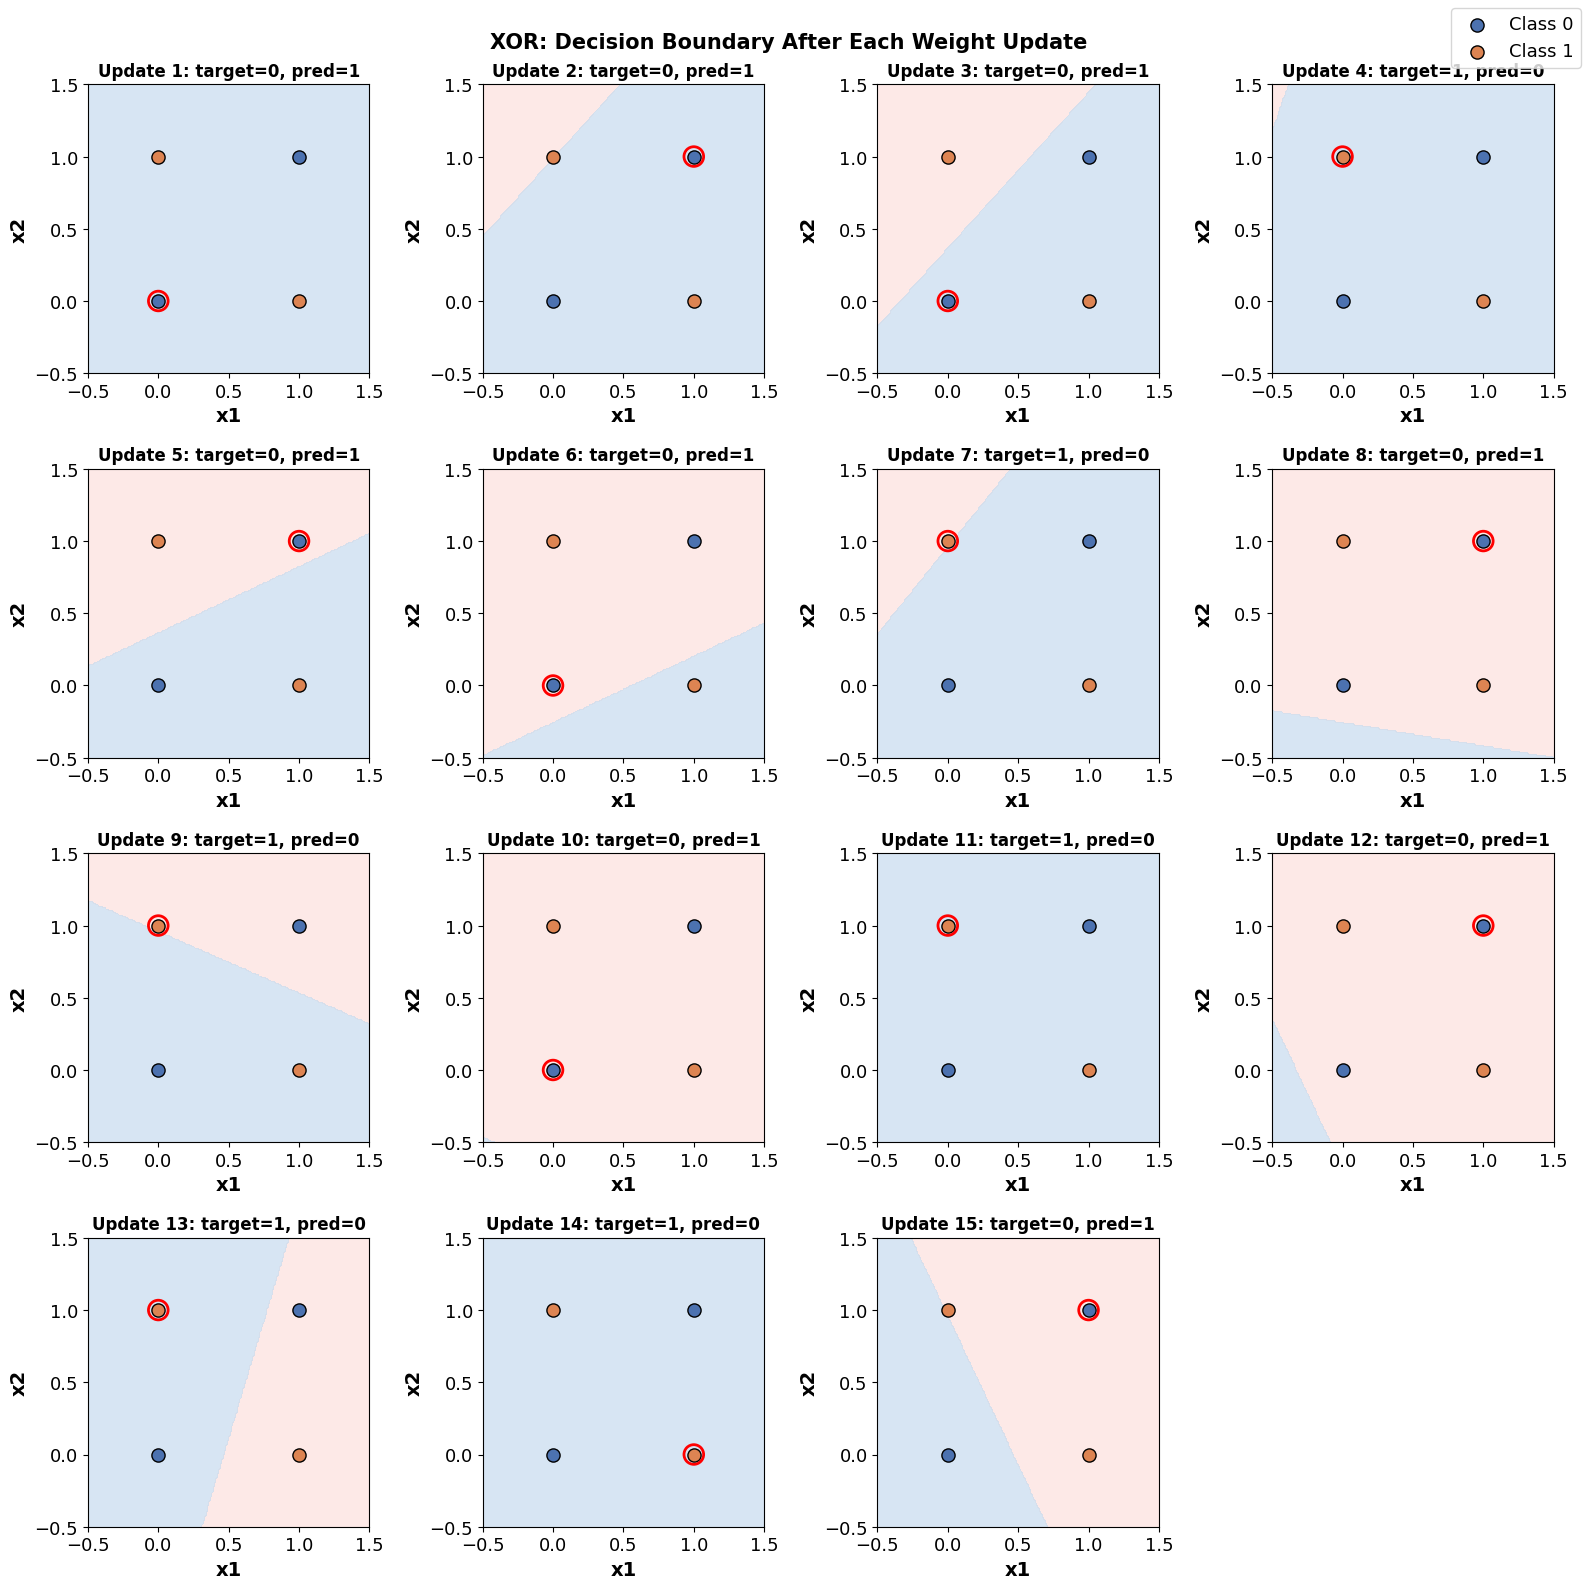

In [27]:
"""
Plots the decision boundary after each of the first 12 XOR weight updates. Unlike
OR/AND, the boundary should visibly oscillate rather than settle.
"""

fig_xor = plot_decision_boundary_sequence(perceptron_xor_log, X_xor, y_xor, "XOR")
if fig_xor is not None:
    save_figure(fig_xor, "10_xor_decision_boundary_updates")
    plt.show()


Saved: figures/11_xor_vs_or_accuracy_oscillation.eps


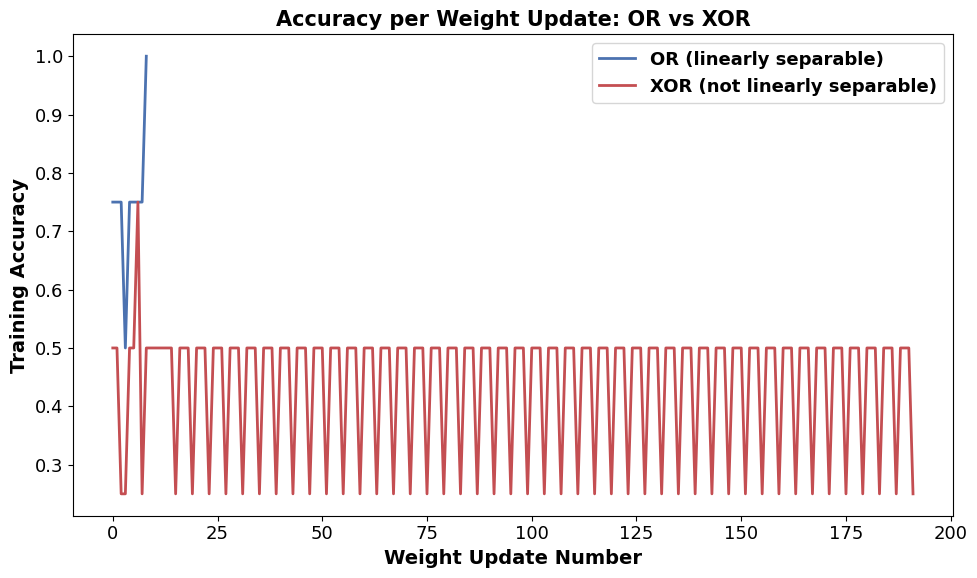

OR final accuracy: 1.00 (reached 1.00 and stayed there: True)
XOR: reached 1.00 at any point: False | final accuracy: 0.25 | number of distinct accuracy values seen: 3


In [28]:
"""
Tracks classification accuracy across a longer XOR training run to show the
oscillation directly: accuracy should repeatedly rise and fall rather than
converge to 100% and stay there, the way OR/AND do.
"""

def accuracy_over_updates(gate_name, X, y, epochs=50, learning_rate=0.1):
    perceptron = Perceptron(n_inputs=X.shape[1], learning_rate=learning_rate)
    accuracies = [np.mean(np.array([perceptron.predict(x) for x in X]) == y)]
    # Re-implement fit here to snapshot accuracy after every single update.
    for epoch in range(epochs):
        for x, target in zip(X, y):
            y_pred = perceptron.predict(x)
            error = target - y_pred
            if error != 0:
                perceptron.w = perceptron.w + perceptron.lr * error * x
                perceptron.b = perceptron.b + perceptron.lr * error
                acc = np.mean(np.array([perceptron.predict(xi) for xi in X]) == y)
                accuracies.append(acc)
    return accuracies

acc_xor = accuracy_over_updates("XOR", X_xor, y_xor, epochs=50)
acc_or = accuracy_over_updates("OR", *GATES["OR"], epochs=20)

fig_acc, ax = plt.subplots(figsize=(10, 6))
ax.plot(acc_or, label="OR (linearly separable)", linewidth=2, color="#4C72B0")
ax.plot(acc_xor, label="XOR (not linearly separable)", linewidth=2, color="#C44E52")
ax.set_xlabel("Weight Update Number", fontweight="bold")
ax.set_ylabel("Training Accuracy", fontweight="bold")
ax.set_title("Accuracy per Weight Update: OR vs XOR", fontweight="bold")
ax.legend()
bold_legend(ax)
fig_acc.tight_layout()
save_figure(fig_acc, "11_xor_vs_or_accuracy_oscillation")
plt.show()

print(f"OR final accuracy: {acc_or[-1]:.2f} (reached 1.00 and stayed there: "
      f"{all(a == 1.0 for a in acc_or[acc_or.index(1.0):])})")
print(f"XOR: reached 1.00 at any point: {1.0 in acc_xor} | "
      f"final accuracy: {acc_xor[-1]:.2f} | "
      f"number of distinct accuracy values seen: {len(set(acc_xor))}")


### Analysis: Why the Perceptron Cannot Converge on XOR

_(Written after inspecting the plots and accuracy trace above — not assumed
beforehand.)_

A single-layer perceptron with a step activation can only ever produce a decision
boundary that is a straight line (in 2-D input space, $w_1x_1 + w_2x_2 + b = 0$).
The perceptron convergence theorem guarantees convergence **only if the two
classes are linearly separable** — i.e., some straight line can separate every
Class-0 point from every Class-1 point.

Plotting the four XOR points — $(0,0)\to0$, $(0,1)\to1$, $(1,0)\to1$, $(1,1)\to0$ —
shows the two Class-1 points sit on opposite corners from the two Class-0 points,
in a diagonal (checkerboard) pattern. No single straight line can separate a
diagonal pair from the other diagonal pair; any line that correctly separates
$(0,1)$ and $(1,0)$ from $(0,0)$ necessarily misclassifies $(1,1)$, and vice versa.

This is exactly the oscillation visible in the accuracy trace above: OR climbs to
100% training accuracy and stays there once a separating line is found, while XOR's
accuracy repeatedly rises to 75% (3 of 4 points correct) and drops back down, because
every weight update that fixes one misclassified point breaks a previously-correct
one. The weight vector keeps moving but never settles, which is why the decision
boundary plot for XOR shows the line sweeping back and forth across the four points
instead of stabilizing like it does for OR/AND.

The practical implication (and the reason MLPs exist) is that XOR requires at least
one hidden layer — a hidden layer lets the network combine two linear boundaries
into a non-linear (piecewise-linear) one that *can* separate the diagonal pattern,
which a single perceptron layer structurally cannot do regardless of learning rate,
epoch count, or initialization.